# HST WFPC2 Calibration Routine

Raw WFPC2 exposure → science-ready image, for exposures `ubai2505m`, `ubai2507m`, `ubai2508m` (chip 0 only).

```
stars + noise = (raw - bias - dark) * flat - sky
```

| Step | Reference | Done here |
|---|---|---|
| 1 | `MASKFILE` | bad pixels (values 2 and 256) set to NaN |
| 2 | `ATODFILE` | **skipped** – `*_raw.fits` is already ADC-corrected |
| 3 | `BLEVFILE` | bias level from overscan, odd and even columns separately |
| 4 | `BIASFILE` | bias image subtracted |
| 5 | `DARKFILE` | dark rate × `EXPTIME` subtracted |
| 6 | `FLATFILE` | multiplied (the WFPC2 flat is an *inverse* sensitivity) |
| 7 | `SHADFILE` | **skipped** – only needed for very short exposures |
| 8 | sky | sigma-clipped median of the calibrated image, subtracted |
| 9 | `PHOTFLAM`, `PHOTZPT`, `ZP_CORR` | counts → flux → STMAG, constants read from the science-ready header |

**Design:** each calibration file is loaded once, every correction is a pure function (array in, array out, no file access or printing), and a single `process_exposure()` runs the chain, writes results to `hst-processed/`, and compares with the science-ready image.

**Author**: Ta'Nasia Coleman

In [ ]:
from collections import OrderedDict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

%matplotlib widget

## Configuration

In [2]:
EXPOSURES = ["ubai2505m", "ubai2507m", "ubai2508m"]
CHIP = 0                                        # we calibrate a single chip

CAL_ROOT = Path("hst-data/calibration")         # <exposure>/<exposure>_raw.fits, _maskfile.fits, ...
SCI_ROOT = Path("hst-data/F336W")               # <exposure>_c0m_aligned.fits (science-ready)
OUT_DIR = Path("hst-processed")                 # calibrated results are written here

DEFECTIVE, QUESTIONABLE = 2, 256                # MASKFILE values (0 = good)
OVERSCAN = (slice(9, 790), slice(8, 14))        # data[row, col] -> rows 10-790, columns 9-14 (1-based)
KEEP_KEYS = ["ROOTNAME", "TARGNAME", "INSTRUME", "DETECTOR", "FILTNAM1",
             "DATE-OBS", "TIME-OBS", "EXPTIME"]  # copied into output headers

## 1. Loading helpers

In [3]:
def first_image_hdu(hdul, order=(0, 1)):
    """Return the first HDU in `order` that holds 2D/3D image data."""
    for i in order:
        if i < len(hdul) and hdul[i].data is not None and hdul[i].data.ndim >= 2:
            return hdul[i]
    raise ValueError(f"No image data found in HDUs {order}")


def load_chip(path, order=(0, 1), chip=CHIP):
    """
    Load one chip of a FITS file as a float64 2D array.
    """
    with fits.open(path) as hdul:
        data = np.array(first_image_hdu(hdul, order).data, dtype=np.float64)
    return data[chip] if data.ndim == 3 else data


def calibration_paths(exposure):
    """All calibration file paths of one exposure, derived from its ID."""
    folder = CAL_ROOT / exposure
    kinds = ("raw", "maskfile", "blevfile", "biasfile", "darkfile", "flatfile")
    return {kind: folder / f"{exposure}_{kind}.fits" for kind in kinds}


def science_path(exposure):
    return SCI_ROOT / f"{exposure}_c0m_aligned.fits"



def get_photometry_keys(science_ready_path):
    """
    Safely extracts the final photometry scaling constants 
    from the metadata header of a processed reference image.
    """
    with fits.open(science_ready_path) as hdul:
        header = hdul[0].header
        header2 = hdul[1].header
        
        # Pull the keys
        photflam = header2.get('PHOTFLAM', 1.0) 
        photzpt = header2.get('PHOTZPT', -21.1)
        zp_corr = header2.get('ZP_CORR', 0.0)
        exposure_time = header.get('EXPTIME', 300)
        
    return photflam, photzpt, zp_corr, exposure_time

## 2. Calibration steps (one pure function per correction)

In [4]:
def apply_mask(data, mask, mask_questionable=True):
    """
    Step 1 - Set bad pixels to NaN so they drop out of all later statistics.
    """
     #If the pixel is Defective or questionable mask all of it
    flags = DEFECTIVE | QUESTIONABLE if mask_questionable else DEFECTIVE
    

    out = data.copy()
    out[(mask.astype(int) & flags) > 0] = np.nan
    return out


def measure_bias_levels(blev):
    """
    Mean overscan level of the odd and even columns.

    'odd' (9, 11, 13) are Python indices
    8, 10, 12 -> overscan[:, 0::2]; 'even' (10, 12, 14) are 9, 11, 13 -> [:, 1::2].
    """
    overscan = blev[OVERSCAN]
    return overscan[:, 0::2].mean(), overscan[:, 1::2].mean()


def subtract_bias_level(data, odd_mean, even_mean):
    """Step 3 - Remove the DC bias level (odd image columns and even ones separately)."""
    out = data.copy()
    out[:, 0::2] -= odd_mean
    out[:, 1::2] -= even_mean
    return out


def subtract_bias_image(data, bias):
    """Step 4 - Remove the bias frame (readout-noise pattern)."""
    return data - bias


def subtract_dark(data, dark, exptime):
    """Step 5 - The dark is a rate, so scale by exposure time before subtracting."""
    return data - dark * exptime


def apply_flat(data, flat):
    """Step 6 - Flat field. The WFPC2 flat is an inverse sensitivity, so multiply."""
    return data * flat


def estimate_sky(data, sigma=3.0, maxiters=5):
    """
    Estimate the sky level of a 2D chip as its sigma-clipped median.
    """
    _, median, _ = sigma_clipped_stats(data, sigma=sigma, maxiters=maxiters,
                                       mask=~np.isfinite(data))
    return median


def subtract_sky(data, sky):
    """Step 8 - Subtract the scalar sky level."""
    return data - sky


def convert_to_flux(data, photflam, exptime):
    """Step 9a - counts -> flux density in erg / s / cm^2 / Angstrom."""
    return data / exptime * photflam


def calculate_safe_mag(flux, photzpt, zp_corr=0.0):
    """Step 9b - STMAG = -2.5 log10(flux) + PHOTZPT + ZP_CORR; NaN where flux <= 0."""
    mag = np.full_like(flux, np.nan)
    positive = flux > 0
    mag[positive] = -2.5 * np.log10(flux[positive]) + photzpt + zp_corr
    return mag

## 3. Pipeline, output and comparison

In [5]:
def calibrate_chip(raw, mask, blev, bias, dark, flat, exptime):
    """
    Run steps 1, 3, 4, 5, 6 and 8

    Returns the image after every step (for plotting) and the derived numbers.
    """
    stages = OrderedDict()
    stages["1. Raw"] = raw
    stages["2. Masked"] = apply_mask(raw, mask)

    odd_mean, even_mean = measure_bias_levels(blev)
    stages["3. Bias level removed"] = subtract_bias_level(stages["2. Masked"], odd_mean, even_mean)
    stages["4. Bias image removed"] = subtract_bias_image(stages["3. Bias level removed"], bias)
    stages["5. Dark removed"] = subtract_dark(stages["4. Bias image removed"], dark, exptime)
    stages["6. Flat-fielded"] = apply_flat(stages["5. Dark removed"], flat)

    sky = estimate_sky(stages["6. Flat-fielded"])          
    stages["7. Sky-subtracted"] = subtract_sky(stages["6. Flat-fielded"], sky)

    info = dict(odd_mean=odd_mean, even_mean=even_mean, sky=sky, exptime=exptime)
    return stages, info


def save_fits(data, path, exposure, raw_path, product, history):
    """Write one float32 product with a small, clean header."""
    raw_header = fits.getheader(raw_path, 0)
    header = fits.Header()
    for key in KEEP_KEYS:
        if key in raw_header:
            header[key] = raw_header[key]
    header["PRODUCT"] = product
    for line in history:
        header.add_history(line)

    path.parent.mkdir(parents=True, exist_ok=True)
    fits.PrimaryHDU(data=data.astype(np.float32), header=header).writeto(path, overwrite=True)
    return path



def compare_to_science(ours, science):
    """Quantitative comparison of our calibrated counts with the science-ready counts."""
    valid = np.isfinite(ours) & np.isfinite(science)
    diff = ours[valid] - science[valid]

    stats = {}
    for name, img in (("ours", ours), ("science", science)):
        _, median, std = sigma_clipped_stats(img, sigma=3.0, mask=~np.isfinite(img))
 
    _, _, stats["clipped_std_diff"] = sigma_clipped_stats(diff, sigma=3.0)
    stats["median_diff"] = np.median(diff)
    stats["correlation"] = np.corrcoef(ours[valid], science[valid])[0, 1]
    stats["n_pixels"] = int(valid.sum())
    return stats


def process_exposure(exposure):
    """Calibrate one exposure, write results to hst-processed/, compare with the science-ready image."""
    paths = calibration_paths(exposure)
    sci = science_path(exposure)

    photflam, photzpt, zp_corr, exptime = get_photometry_keys(sci)
    

    # each file is read
    raw = load_chip(paths["raw"], order=(1, 0))
    blev = load_chip(paths["blevfile"], order=(1, 0))
    mask, bias, dark, flat = (load_chip(paths[k]) for k in ("maskfile", "biasfile", "darkfile", "flatfile"))
    science = load_chip(sci, order=(1, 0))

    stages, info = calibrate_chip(raw, mask, blev, bias, dark, flat, exptime)
    counts = stages["7. Sky-subtracted"]
    flux = convert_to_flux(counts, photflam, exptime)
    mag = calculate_safe_mag(flux, photzpt, zp_corr)

    history = [f"Calibrated from {paths['raw'].name}, chip {CHIP}",
               "Steps: mask, bias level, bias, dark, flat, sky (ADC, shading skipped)",
               f"EXPTIME={exptime} sky={info['sky']:.4f} counts"]
    outputs = {
        "calibrated": (counts, "Calibrated counts (DN)"),
        "flux": (flux, "Flux density erg/s/cm2/A"),
        "mag": (mag, "STMAG"),
    }
    saved = [save_fits(data, OUT_DIR / f"{exposure}_{name}.fits", exposure, paths["raw"], label, history)
             for name, (data, label) in outputs.items()]

    return dict(exposure=exposure, stages=stages, info=info, flux=flux, mag=mag,
                science=science, stats=compare_to_science(counts, science),
                constants=dict(photflam=photflam, photzpt=photzpt, zp_corr=zp_corr),
                saved=saved)

## 4. Plotting helpers

In [6]:
def plot_stages(stages, info, title, percentiles=(1, 99)):
    """Every calibration stage on one figure, plus the sky-estimation histogram."""
    fig, axes = plt.subplots(2, 3, figsize=(9, 9), constrained_layout=True)
    flat_axes = axes.ravel()

    for ax, (label, img) in zip(flat_axes, stages.items()):
        vmin, vmax = np.nanpercentile(img, percentiles)
        im = ax.imshow(img, origin="lower", vmin=vmin, vmax=vmax)
        ax.set_title(f"{label}\n[{vmin:.1f}, {vmax:.1f}]", fontsize=11)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

    flat_img = stages["6. Flat-fielded"]
    values = flat_img[np.isfinite(flat_img)]
    _, _, std = sigma_clipped_stats(values, sigma=3.0)
 
    fig.suptitle(title, fontsize=16)
    return fig


def plot_mask(mask, raw, title, percentiles=(1, 95)):
    """Raw exposure next to its bad-pixel mask."""
    cmap = ListedColormap(["black", "pink", "cyan"])
    norm = BoundaryNorm([-0.1, 0.1, 2.1, 257], cmap.N)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
    vmin, vmax = np.percentile(raw, percentiles)
    ax1.imshow(raw, origin="lower", vmin=vmin, vmax=vmax)
    ax1.set_title("Raw")
    ax2.imshow(mask, origin="lower", cmap=cmap, norm=norm, interpolation="nearest")
    ax2.set_title("MASKFILE")
    ax2.legend(handles=[Patch(color="black", label="0 good"),
                        Patch(color="pink", label="2 defective"),
                        Patch(color="cyan", label="256 questionable")], loc="upper right")
    fig.suptitle(title)
    return fig


def plot_comparison(ours, science, title, percentiles=(1, 99)):
    """Our calibrated counts vs science-ready: both images, their difference, and its histogram."""
    diff = ours - science
    vmin, vmax = np.nanpercentile(science, percentiles)
    dlim = np.nanpercentile(np.abs(diff), 99)

    fig, axes = plt.subplots(2, 2, figsize=(14, 13), constrained_layout=True)
    axes[0, 0].imshow(ours, origin="lower", vmin=vmin, vmax=vmax)
    axes[0, 0].set_title("Our calibration")
    axes[0, 1].imshow(science, origin="lower", vmin=vmin, vmax=vmax)
    axes[0, 1].set_title("Science-ready")
    im = axes[1, 0].imshow(diff, origin="lower", cmap="RdBu_r", vmin=-dlim, vmax=dlim)
    axes[1, 0].set_title("Difference (ours - science-ready)")
    fig.colorbar(im, ax=axes[1, 0], fraction=0.046)
    axes[1, 1].hist(diff[np.isfinite(diff)], bins=np.linspace(-dlim, dlim, 200))
    axes[1, 1].set_yscale("log")
    axes[1, 1].set_title("Histogram of differences")
    axes[1, 1].set_xlabel("counts")
    fig.suptitle(title, fontsize=16)
    return fig

## 5. Look at the mask (step 1)

Mask values and pixel counts: {np.int64(0): np.int64(635890), np.int64(2): np.int64(1169), np.int64(256): np.int64(2941)}


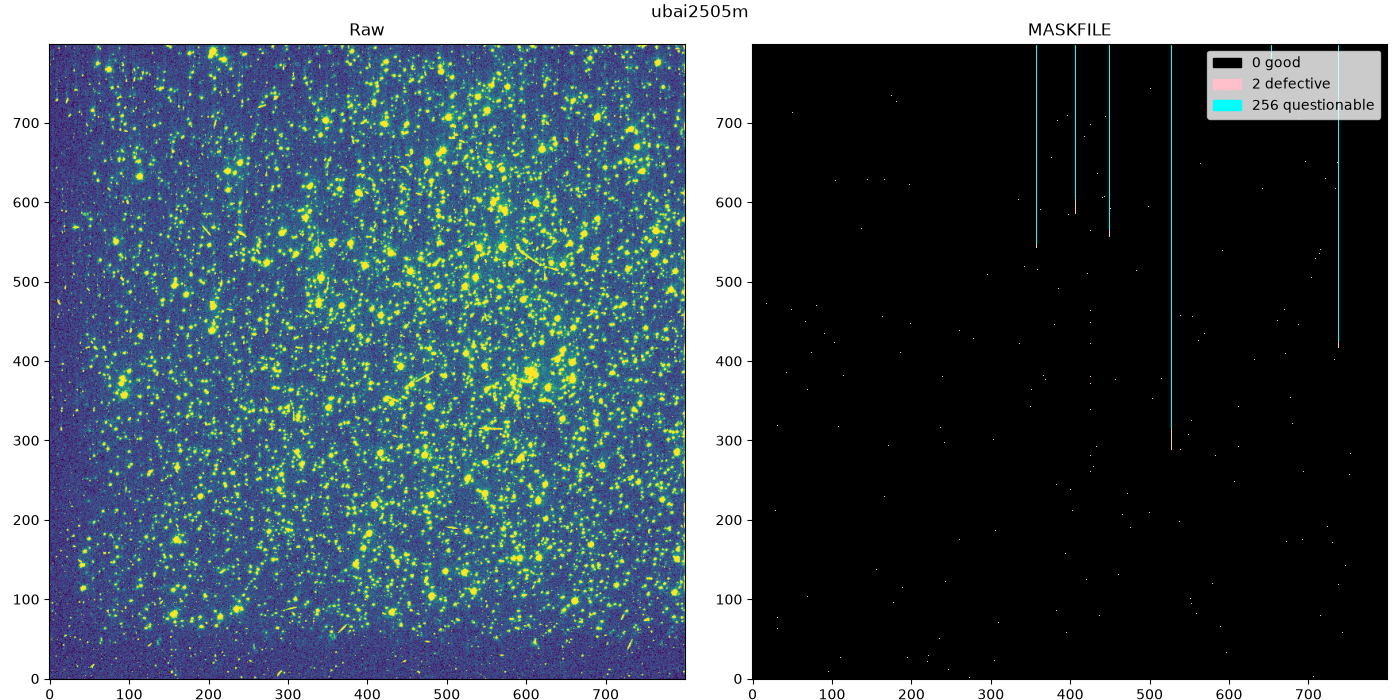

In [7]:
exposure = EXPOSURES[0]
paths = calibration_paths(exposure)
mask = load_chip(paths["maskfile"])
raw = load_chip(paths["raw"], order=(1, 0))

values, counts = np.unique(mask.astype(int), return_counts=True)
print("Mask values and pixel counts:", dict(zip(values, counts)))
plot_mask(mask, raw, exposure)
plt.show()


## 6. Run the pipeline on all exposures

In [8]:
results = {exp: process_exposure(exp) for exp in EXPOSURES}

for exp, res in results.items():
    print(f"{exp}: sky = {res['info']['sky']:.3f} counts, EXPTIME = {res['info']['exptime']} s, "
          f"constants = {res['constants']}")
    for path in res["saved"]:
        print("   wrote", path)

1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]
1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]
1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


ubai2505m: sky = 0.738 counts, EXPTIME = 700.0 s, constants = {'photflam': 1.115396e-16, 'photzpt': -21.1, 'zp_corr': -0.03288031}
   wrote hst-processed\ubai2505m_calibrated.fits
   wrote hst-processed\ubai2505m_flux.fits
   wrote hst-processed\ubai2505m_mag.fits
ubai2507m: sky = 0.778 counts, EXPTIME = 700.0 s, constants = {'photflam': 1.115396e-16, 'photzpt': -21.1, 'zp_corr': -0.03288031}
   wrote hst-processed\ubai2507m_calibrated.fits
   wrote hst-processed\ubai2507m_flux.fits
   wrote hst-processed\ubai2507m_mag.fits
ubai2508m: sky = 0.732 counts, EXPTIME = 700.0 s, constants = {'photflam': 1.115396e-16, 'photzpt': -21.1, 'zp_corr': -0.03288031}
   wrote hst-processed\ubai2508m_calibrated.fits
   wrote hst-processed\ubai2508m_flux.fits
   wrote hst-processed\ubai2508m_mag.fits


## 7. All calibration stages side by side

In [9]:
#for exp, res in results.items():
#    plot_stages(res["stages"], res["info"], f"{exp}, chip {CHIP}")
#    plt.show()

# 1. Define your output directory
OUT_DIR = Path("hst-processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)


IMAGE_PERCENTILES = [1, 99] 

for exp, res in results.items():
    # Fix: Pass percentiles as the 4th argument instead of the chip string
    plot_stages(res["stages"], res["info"], f"{exp}", IMAGE_PERCENTILES)
    
    # Use this to name the file based on the exposure
    plot_filename = OUT_DIR / f"{exp}_chip{CHIP}_stages.png"
    
    # Save and clean up
    plt.savefig(plot_filename, bbox_inches="tight", dpi=300)
    plt.close()
    
    print(f"Saved plot to: {plot_filename}")


Saved plot to: hst-processed\ubai2505m_chip0_stages.png
Saved plot to: hst-processed\ubai2507m_chip0_stages.png
Saved plot to: hst-processed\ubai2508m_chip0_stages.png


## 8. Compare with the science-ready images

In [10]:
# 1. Ensure your output directory exists
OUT_DIR = Path("hst-processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- PART 1: Save the summary table to a text file ---
rows = ["median_diff", "clipped_std_diff", "correlation", "n_pixels"]
log_filename = OUT_DIR / f"chip{CHIP}_comparison_stats.txt"

# Build the text table string
table_text = f"{'':20s}" + "".join(f"{exp:>14s}" for exp in EXPOSURES) + "\n"
for key in rows:
    table_text += f"{key:20s}" + "".join(f"{results[exp]['stats'][key]:14.4f}" for exp in EXPOSURES) + "\n"

# Write the table to the text file
log_filename.write_text(table_text)
print(f"Saved stats summary to: {log_filename}")


# --- PART 2: Loop through results, generate, and save the comparison plots ---
for exp, res in results.items():
    # Call your comparison plotting function
    plot_comparison(res["stages"]["7. Sky-subtracted"], res["science"], f"{exp}: calibrated vs science-ready")
    
    # Define a clean filename 
    plot_filename = OUT_DIR / f"{exp}_chip{CHIP}_comparison.png"
    
    # Save the figure to the specified directory
    plt.savefig(plot_filename, bbox_inches="tight", dpi=300)
    plt.close()  # Clear memory
    
    print(f"Saved plot to: {plot_filename}")


Saved stats summary to: hst-processed\chip0_comparison_stats.txt
Saved plot to: hst-processed\ubai2505m_chip0_comparison.png
Saved plot to: hst-processed\ubai2507m_chip0_comparison.png
Saved plot to: hst-processed\ubai2508m_chip0_comparison.png


### Magnitudes

The same flux → STMAG conversion is applied to both images, so any offset reflects differences in the counts, not the photometry. The 1st-99th percentile stretch avoids being dominated by single-pixel extremes.

In [11]:
def normalize_data(x, pmin=None, pmax=None):
    """Normalize data to [0, 1] between the given percentiles (default: min and max)."""
    res = np.asarray(x, dtype=np.float64)
    pmin = 0 if pmin is None else pmin
    pmax = 100 if pmax is None else pmax
    vmin, vmax = np.nanpercentile(res, [pmin, pmax])
    if vmin == vmax:
        return np.zeros_like(res)
    return np.clip((res - vmin) / (vmax - vmin), 0, 1)


def plot_magnitude_comparison(calibrated_mag, science_mag, title, pmin=1, pmax=99):
    """Calibrated and science-ready magnitude images side by side, same stretch."""
    cal = calibrated_mag
    sci = science_mag
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True, constrained_layout=True)
    axes[0].imshow(normalize_data(cal, pmin, pmax), origin="lower")
    axes[0].set_title("Calibrated magnitude")
    axes[1].imshow(normalize_data(sci, pmin, pmax), origin="lower")
    axes[1].set_title("Science-ready magnitude")
    fig.suptitle(title)
    return fig

# --- PART 2: Loop through results, generate, and save the comparison plots ---
for exp, res in results.items():

    consts = res["constants"]
    flux_sci = convert_to_flux(res["science"], consts["photflam"], res["info"]["exptime"])
    mag_sci = calculate_safe_mag(flux_sci, consts["photzpt"], consts["zp_corr"])
    plot_magnitude_comparison(res["mag"], mag_sci, f"{exp}: STMAG")
    
    
    plot_filename = OUT_DIR / f"{exp}_chip{CHIP}_magnitude_comparison.png"
    
    
    plt.savefig(plot_filename, bbox_inches="tight", dpi=300)
    plt.close()  # Clear memory
    
    print(f"Saved plot to: {plot_filename}")

Saved plot to: hst-processed\ubai2505m_chip0_magnitude_comparison.png
Saved plot to: hst-processed\ubai2507m_chip0_magnitude_comparison.png
Saved plot to: hst-processed\ubai2508m_chip0_magnitude_comparison.png
